# Basic CNN vs MLP ? FashionMNIST

Additional experiment: compare convolutional features with the existing MLP baseline (run 10), wider MLP (11) and deeper MLP (12).

Run cells from top to bottom. Uses the existing dataset and exact stratified split; no augmentation or pretrained weights. Full training is 50 epochs. Test is disabled until you explicitly enable it after validation review.


In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn, optim
from torch.utils.data import DataLoader

# Works from workspace root, project root or a child directory.
root = Path.cwd().resolve()
while not (root / 'src' / 'data.py').exists():
    if (root / 'practice_1_fashionmnist' / 'src' / 'data.py').exists():
        root = root / 'practice_1_fashionmnist'
        break
    if root == root.parent:
        raise FileNotFoundError('Open this notebook inside the DL workspace.')
    root = root.parent
sys.path.insert(0, str(root / 'src'))
from data import build_loaders
from metrics import evaluate, classification_metrics
from logger import open_log, log_setup, log_epoch

settings = dict(seed=42, epochs=50, batch_size=64, lr=0.001,
                weight_decay=1e-5, dropout=0.2, decay_step=15, decay_gamma=0.3, num_workers=2)
data_settings = dict(seed=42, val_size=0.1, batch_size=settings['batch_size'])
torch.manual_seed(settings['seed'])
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

Device: cuda


## 1. Same data as MLP

54,000 train / 6,000 validation / 10,000 official test. Images remain N x 1 x 28 x 28, with ToTensor only.

Loading speed: `num_workers=2` prepares training batches in parallel; persistent workers avoid restarting each epoch. Pinned CPU memory and non-blocking CUDA copies help overlap data transfer. If Windows kernel workers fail or RAM is tight, set `num_workers=0`. More workers are not always faster. Apply changes only after the running cell finishes or you interrupt it yourself; restarting train creates a fresh run, not a resume.


In [2]:
# Workers prepare batches while the GPU trains on the previous batch.
# Windows: keep dataset classes in importable data.py. Use 0 if worker startup fails.
def make_loaders(data_config, num_workers):
    train, val, test = build_loaders(data_config)
    pin = device.type == 'cuda'
    train = DataLoader(
        train.dataset, batch_size=train.batch_size, shuffle=True,
        generator=torch.Generator().manual_seed(data_config['seed']),
        num_workers=num_workers, pin_memory=pin,
        persistent_workers=num_workers > 0,
        **({'prefetch_factor': 2} if num_workers > 0 else {}),
    )
    # Small validation/test sets do not keep extra worker processes alive.
    val = DataLoader(val.dataset, batch_size=val.batch_size, pin_memory=pin)
    test = DataLoader(test.dataset, batch_size=test.batch_size, pin_memory=pin)
    return train, val, test

train_loader, val_loader, test_loader = make_loaders(data_settings, settings['num_workers'])
print('Split sizes:', *(len(loader.dataset) for loader in [train_loader, val_loader, test_loader]))
print('Train workers:', train_loader.num_workers, '| Pinned memory:', train_loader.pin_memory)


Split sizes: 54000 6000 10000
Train workers: 2 | Pinned memory: True


## 2. Small CNN: backbone + classification head

| Stage | Shape for one image |
|---|---|
| Input | 1 x 28 x 28 |
| Conv 3x3 + ReLU | 16 x 28 x 28 |
| MaxPool 2x2 | 16 x 14 x 14 |
| Conv 3x3 + ReLU | 32 x 14 x 14 |
| MaxPool 2x2: backbone output | 32 x 7 x 7 |
| Flatten + Linear + ReLU + Dropout | 64 |
| Linear: logits | 10 |

Unlike flattening before learning in MLP, convolution learns local shared filters while feature maps retain spatial axes. Pooling reduces spatial resolution; it does **not** preserve every pixel or guarantee better accuracy. Flattening happens only after feature extraction.


In [3]:
class BasicCNN(nn.Module):
    def __init__(self, dropout=0.2):
        super().__init__()
        self.backbone = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(32 * 7 * 7, 64)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout)
        self.fc2 = nn.Linear(64, 10)

    def forward(self, images):
        x = self.backbone(images)
        x = self.flatten(x)
        x = self.fc1(x)
        x = self.relu(x)
        x = self.dropout(x)
        x = self.fc2(x)
        return x

model = BasicCNN(settings['dropout']).to(device)
print(model)
print('Parameters:', sum(p.numel() for p in model.parameters()))
with torch.no_grad():
    x = torch.zeros(1, 1, 28, 28, device=device)
    for layer in model.backbone:
        x = layer(x)
        print(type(layer).__name__, tuple(x.shape))

BasicCNN(
  (backbone): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=1568, out_features=64, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.2, inplace=False)
  (fc2): Linear(in_features=64, out_features=10, bias=True)
)
Parameters: 105866
Conv2d (1, 16, 28, 28)
ReLU (1, 16, 28, 28)
MaxPool2d (1, 16, 14, 14)
Conv2d (1, 32, 14, 14)
ReLU (1, 32, 14, 14)
MaxPool2d (1, 32, 7, 7)


## 3. Train and validate

Same optimizer, LR schedule and checkpoint criterion as MLP 10?12. Each execution creates a new outputs/cnn_runs/lan_N directory. No MLP run is overwritten. One log line per epoch.


In [4]:
# Rerunning this cell starts a fresh experiment, including model and shuffle seed.
torch.manual_seed(settings['seed'])
train_loader, val_loader, test_loader = make_loaders(data_settings, settings['num_workers'])
model = BasicCNN(settings['dropout']).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=settings['lr'], weight_decay=settings['weight_decay'])
scheduler = optim.lr_scheduler.StepLR(optimizer, settings['decay_step'], settings['decay_gamma'])

runs = root / 'outputs' / 'cnn_runs'
runs.mkdir(exist_ok=True)
number = 1
while (runs / f'lan_{number}').exists():
    number += 1
folder = runs / f'lan_{number}'
folder.mkdir()
logger = open_log(folder, 'train.log')
log_setup(logger, model, criterion, optimizer, scheduler,
          dict(model='BasicCNN', settings=settings, data_config=data_settings), device)
best_score = (-1.0, float('-inf'))
best_epoch = 0
history = []

for epoch in range(1, settings['epochs'] + 1):
    model.train()
    total_loss = torch.zeros((), device=device)
    correct = torch.zeros((), dtype=torch.long, device=device)

    for images, labels in train_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.detach() * len(labels)
        correct += (outputs.argmax(1) == labels).sum()

    val = evaluate(model, val_loader, device)
    row = dict(epoch=epoch, train_loss=total_loss.item() / len(train_loader.dataset),
               train_accuracy=correct.item() / len(train_loader.dataset),
               val_loss=val['loss'], val_accuracy=val['accuracy'],
               lr=optimizer.param_groups[0]['lr'])
    history.append(row)
    checkpoint = dict(model_state=model.state_dict(), settings=dict(settings),
                      data_config=dict(data_settings), epoch=epoch, validation=val,
                      selection='val_accuracy_then_val_loss', architecture=str(model))
    score = (val['accuracy'], -val['loss'])
    if score > best_score:
        best_score, best_epoch = score, epoch
        torch.save(checkpoint, folder / 'best.pt')

    log_epoch(logger, row, best_epoch, settings['epochs'])
    scheduler.step()
    (folder / 'metrics.json').write_text(json.dumps(history, indent=2), encoding='utf-8')

torch.save(checkpoint, folder / 'model.pt')
logger.info('Finished | best_epoch=%d | output=%s', best_epoch, folder)

2026-10-21 15:22:57,174 | Configuration: {'model': 'BasicCNN', 'settings': {'seed': 42, 'epochs': 50, 'batch_size': 64, 'lr': 0.001, 'weight_decay': 1e-05, 'dropout': 0.2, 'decay_step': 15, 'decay_gamma': 0.3, 'num_workers': 2}, 'data_config': {'seed': 42, 'val_size': 0.1, 'batch_size': 64}}
2026-10-21 15:22:57,175 | Device: cuda | GPU: Quadro T2000 | PyTorch: 2.14.1+cu130
2026-10-21 15:22:57,175 | Model: BasicCNN(
  (backbone): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=1568, out_features=64, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.2, inplace=False)
  (fc2): Linear(in_features=64, ou

## 4. Reload best checkpoint and compare

Train metrics below use eval mode, matching the MLP review. Choose configurations by validation, not test. Missing test values mean unmeasured, not zero.


In [5]:
saved = torch.load(folder / 'best.pt', map_location=device, weights_only=True)
model = BasicCNN(saved['settings']['dropout']).to(device)
model.load_state_dict(saved['model_state'])
model.eval()
train_loader, val_loader, test_loader = make_loaders(saved['data_config'], 0)
train_eval = DataLoader(train_loader.dataset, batch_size=256, shuffle=False)
scores = dict(train=evaluate(model, train_eval, device),
              validation=evaluate(model, val_loader, device))
assert abs(scores['validation']['accuracy'] - saved['validation']['accuracy']) < 1e-12

# Enable only after reviewing validation and deciding to evaluate this checkpoint.
RUN_TEST = False
if RUN_TEST:
    scores['test'] = evaluate(model, test_loader, device)

review = json.loads((root / 'outputs' / 'run_review.json').read_text(encoding='utf-8'))
rows = []
for run in review['runs']:
    if run['run'] in ['lan_10', 'lan_11', 'lan_12']:
        rows.append(dict(Model='MLP ' + run['run'], **{
            split + '_' + metric: result[metric]
            for split, result in run['splits'].items() for metric in ['accuracy', 'loss']}))
rows.append(dict(Model='CNN ' + folder.name, **{
    split + '_' + metric: result[metric]
    for split, result in scores.items() for metric in ['accuracy', 'loss']}))
comparison = pd.DataFrame(rows).set_index('Model')
display(comparison.round(4))
comparison.to_csv(folder / 'comparison.csv')
(folder / 'result.json').write_text(json.dumps(dict(best_epoch=saved['epoch'], scores=scores), indent=2))
eval_logger = open_log(folder, 'evaluate.log')
for split, result in scores.items():
    eval_logger.info('%s | best_epoch=%d | %s', split, saved['epoch'], result)

,train_accuracy,train_loss,validation_accuracy,validation_loss,test_accuracy,test_loss
Model,,,,,,
MLP lan_10,0.9515,0.1280,0.9133,0.2780,NaN,NaN
MLP lan_11,0.9678,0.0863,0.9148,0.3082,0.9005,0.3603
MLP lan_12,0.9619,0.1009,0.9173,0.2992,0.9017,0.3570
CNN lan_2,0.9753,0.0725,0.9322,0.2236,NaN,NaN


2026-10-21 15:27:20,382 | train | best_epoch=38 | {'loss': 0.07251086848091196, 'accuracy': 0.9752777777777778, 'count': 54000}
2026-10-21 15:27:20,382 | validation | best_epoch=38 | {'loss': 0.2236023323237896, 'accuracy': 0.9321666666666667, 'count': 6000}


## 5. Learning curves and validation errors

Confusion rows are true labels, columns are predictions. Show actual mistakes, including Shirt versus T-shirt/Pullover.


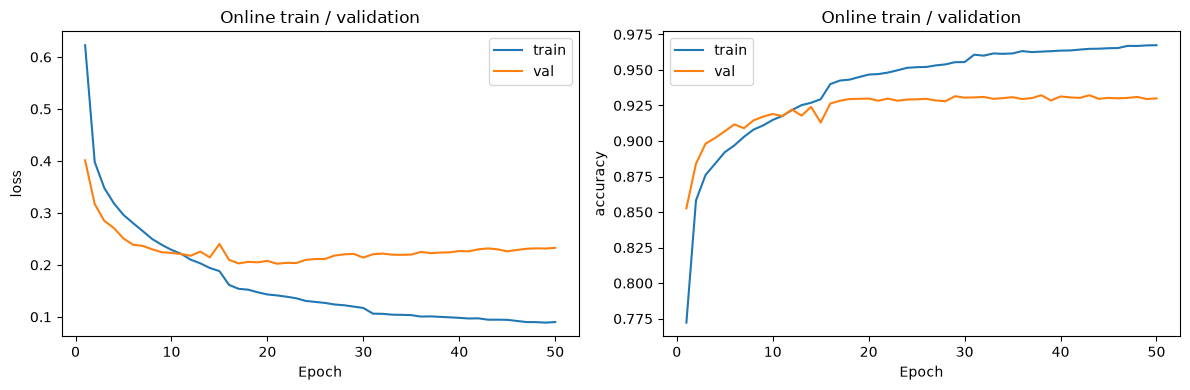

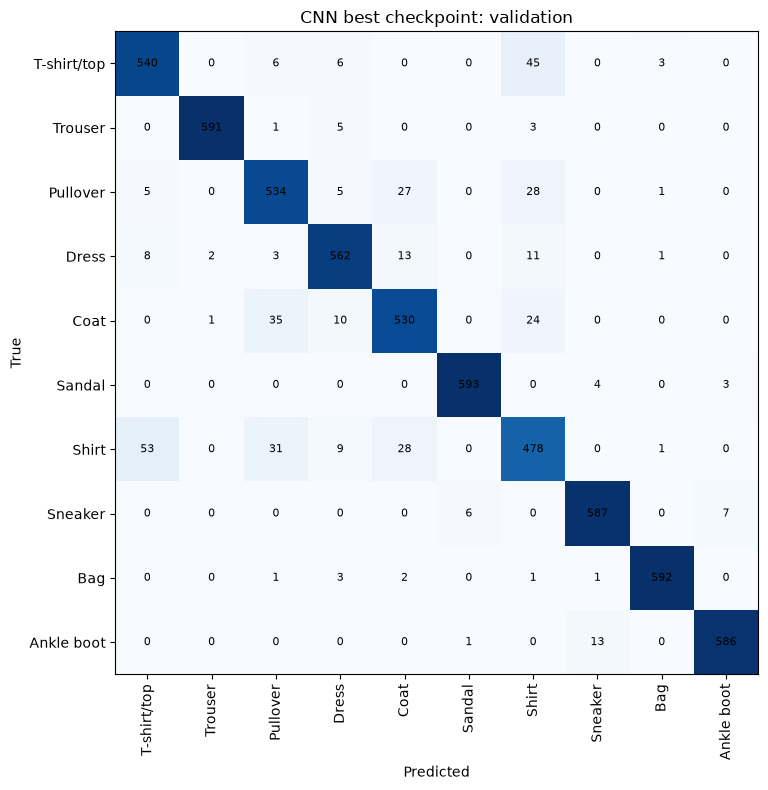

,precision,recall,f1,support,TP,TN,FP,FN
T-shirt/top,0.8911,0.9000,0.8955,600,540,5334,66,60
Trouser,0.9949,0.9850,0.9899,600,591,5397,3,9
Pullover,0.8740,0.8900,0.8819,600,534,5323,77,66
Dress,0.9367,0.9367,0.9367,600,562,5362,38,38
Coat,0.8833,0.8833,0.8833,600,530,5330,70,70
Sandal,0.9883,0.9883,0.9883,600,593,5393,7,7
Shirt,0.8102,0.7967,0.8034,600,478,5288,112,122
Sneaker,0.9702,0.9783,0.9743,600,587,5382,18,13
Bag,0.9900,0.9867,0.9883,600,592,5394,6,8
Ankle boot,0.9832,0.9767,0.9799,600,586,5390,10,14


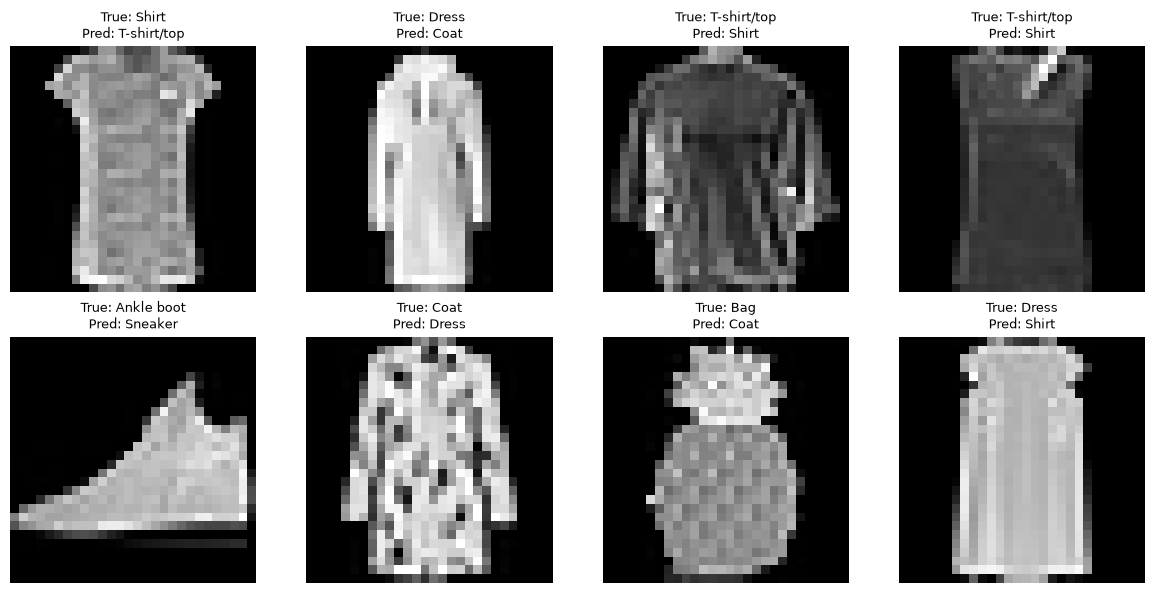

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ['loss', 'accuracy']):
    for split in ['train', 'val']:
        ax.plot([r['epoch'] for r in history], [r[split + '_' + metric] for r in history], label=split)
    ax.set(xlabel='Epoch', ylabel=metric, title='Online train / validation')
    ax.legend()
fig.tight_layout()
fig.savefig(folder / 'curves.png')
plt.show()

names = review['names']
matrix = torch.zeros(10, 10, dtype=torch.int64)
mistakes = []
with torch.no_grad():
    for images, labels in val_loader:
        predictions = model(images.to(device)).argmax(1).cpu()
        matrix += torch.bincount(labels * 10 + predictions, minlength=100).reshape(10, 10)
        for image, true, pred in zip(images, labels, predictions):
            if true != pred and len(mistakes) < 8:
                mistakes.append((image[0], int(true), int(pred)))
assert matrix.sum().item() == len(val_loader.dataset)
fig, ax = plt.subplots(figsize=(9, 8))
ax.imshow(matrix, cmap='Blues')
for i in range(10):
    for j in range(10):
        ax.text(j, i, matrix[i, j].item(), ha='center', va='center', fontsize=8)
ax.set(xticks=range(10), yticks=range(10), xticklabels=names, yticklabels=names,
       xlabel='Predicted', ylabel='True', title='CNN best checkpoint: validation')
plt.setp(ax.get_xticklabels(), rotation=90)
fig.tight_layout()
fig.savefig(folder / 'confusion.png')
plt.show()
class_scores = classification_metrics(matrix)
(folder / 'validation_errors.json').write_text(json.dumps(dict(confusion=matrix.tolist(), **class_scores), indent=2))
display(pd.DataFrame(class_scores['classes'], index=names).round(4))

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax in axes.flat:
    ax.axis('off')
for ax, (image, true, pred) in zip(axes.flat, mistakes):
    ax.imshow(image, cmap='gray')
    ax.set_title(f'True: {names[true]}\nPred: {names[pred]}', fontsize=9)
fig.tight_layout()
fig.savefig(folder / 'mistakes.png')
plt.show()

## 6. Inspect the learned backbone

First validation image and eight final feature channels. Each channel is a 7x7 learned spatial map, not a class label or proof of interpretable object parts. Grayscale scaling is independent per subplot.


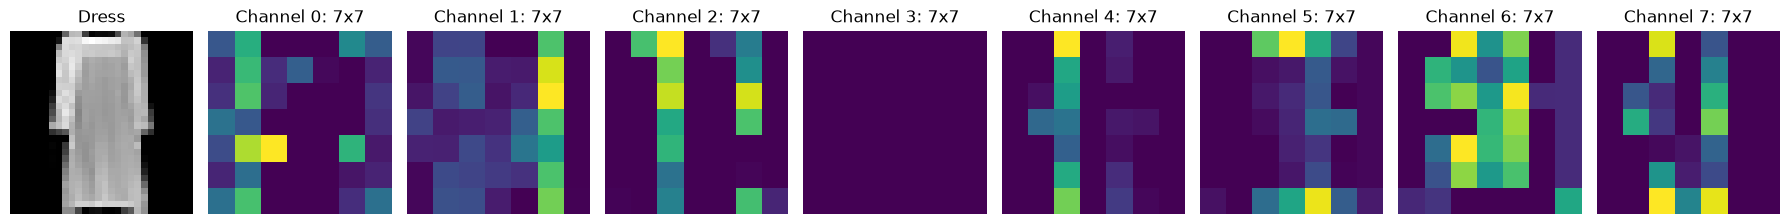

In [7]:
image, label = val_loader.dataset[0]
with torch.no_grad():
    features = model.backbone(image.unsqueeze(0).to(device)).cpu()[0]
fig, axes = plt.subplots(1, 9, figsize=(18, 3))
axes[0].imshow(image[0], cmap='gray')
axes[0].set_title(names[label])
for i, ax in enumerate(axes[1:]):
    ax.imshow(features[i], cmap='viridis')
    ax.set_title(f'Channel {i}: 7x7')
for ax in axes:
    ax.axis('off')
fig.tight_layout()
fig.savefig(folder / 'feature_maps.png')
plt.show()

## Discussion for the lab

- Does validation accuracy improve over MLP 10/11/12, and does loss improve too?
- Is the train-validation gap smaller? Does Shirt recall improve instead of only total accuracy?
- Explain locality, weight sharing and the 28x28 -> 14x14 -> 7x7 feature hierarchy.
- Report actual results only. A small CNN can help with image structure, but improvement is not guaranteed; architecture, parameter count and dropout placement also differ from MLP.
- One seed is exploratory evidence, not proof of general superiority. Existing MLP test scores have already been viewed; do not tune CNN on test.
